In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

/home/luca/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [3]:
file_path = "3dharmonic.csv"

df = pd.read_csv(file_path, sep=";")

# Remove any accidental whitespace from column names
df.columns = df.columns.str.strip()

# Inspect the result
with pd.option_context('display.max_rows', None):
    display(pd.DataFrame(df.columns, columns=["Column Name"]))

,Column Name
0,Default_angularAcceleration_x
1,Default_angularAcceleration_y
2,Default_angularAcceleration_z
3,Default_angularVelocity_x
4,Default_angularVelocity_y
5,Default_angularVelocity_z
6,Default_linearAcceleration_x
7,Default_linearAcceleration_y
8,Default_linearAcceleration_z
9,Default_linearVelocity_x


In [4]:
forceCurrent = df["cooperative_ForceInternal_Current"].tolist()
forceReference = df["cooperative_ForceInternal_Reference"].tolist()
time = df["t"].tolist()

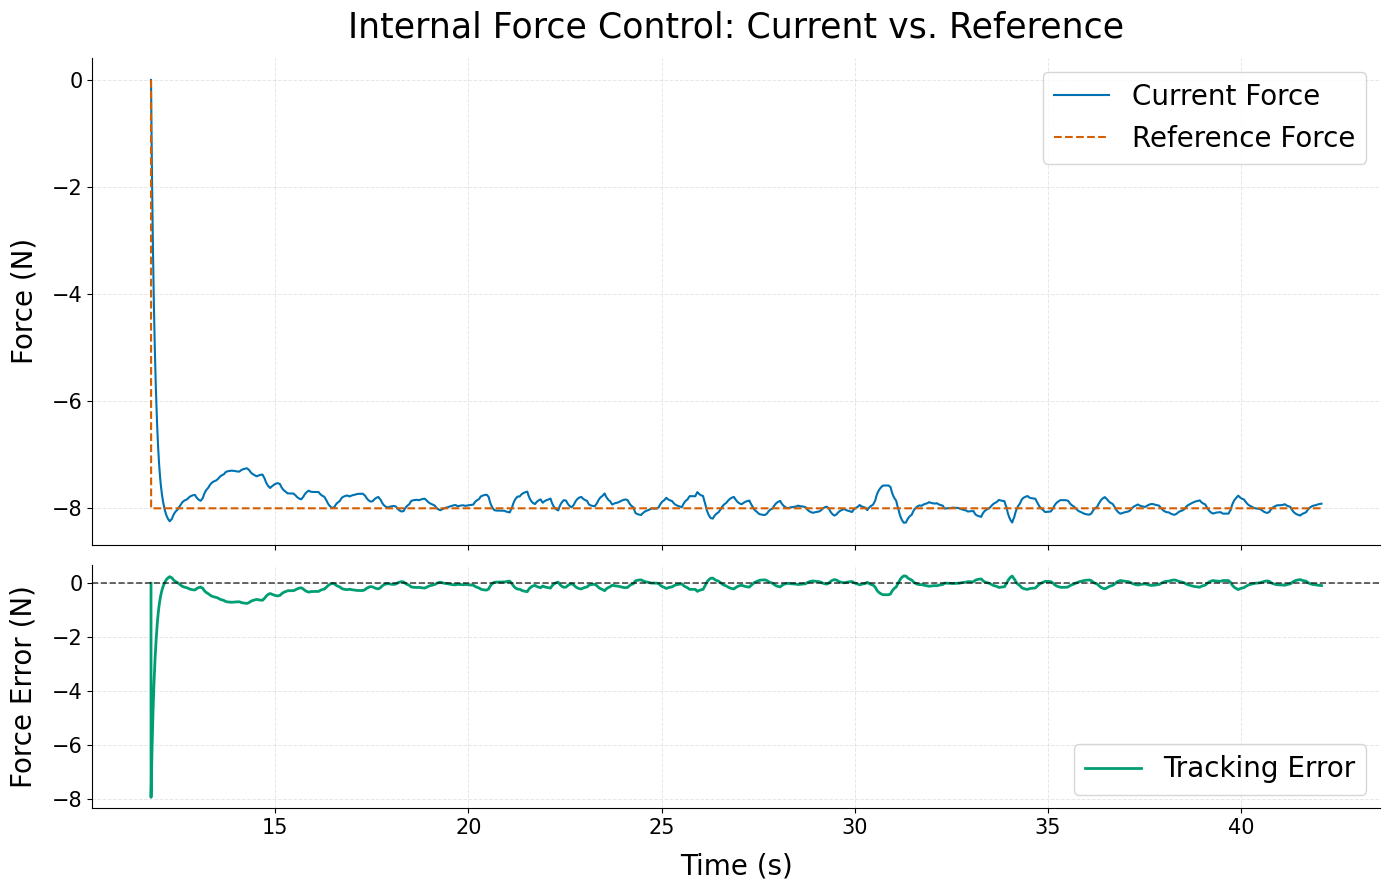

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Convert lists to NumPy arrays
time_array = np.array(time)
force_current = np.array(forceCurrent)
force_reference = np.array(forceReference)

# Calculate tracking error
forceError = force_reference - force_current

# Create two vertically stacked subplots
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(14, 9),
    dpi=100,
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

# --------------------------------------------------
# First subplot: Current and reference forces
# --------------------------------------------------
ax1.plot(
    time_array,
    force_current,
    label="Current Force",
    color="#0072B2",
    linewidth=1.5
)

ax1.plot(
    time_array,
    force_reference,
    label="Reference Force",
    color="#D55E00",
    linewidth=1.5,
    linestyle="--"
)

ax1.set_title("Internal Force Control: Current vs. Reference", fontsize=25, pad=15)
ax1.set_ylabel("Force (N)", fontsize=20, labelpad=10)
ax1.tick_params(axis="both", labelsize=15)
ax1.legend(fontsize=20, frameon=True, loc="best")
ax1.grid(True, linestyle="--", linewidth=0.7, alpha=0.3)

# --------------------------------------------------
# Second subplot: Tracking error
# --------------------------------------------------
ax2.plot(
    time_array,
    forceError,
    label="Tracking Error",
    color="#009E73",
    linewidth=2
)

# Zero-error reference line
ax2.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    alpha=0.7
)

ax2.set_xlabel("Time (s)", fontsize=20, labelpad=10)
ax2.set_ylabel("Force Error (N)", fontsize=20, labelpad=10)
ax2.tick_params(axis="both", labelsize=15)
ax2.legend(fontsize=20, frameon=True, loc="best")
ax2.grid(True, linestyle="--", linewidth=0.7, alpha=0.3)

# Clean appearance
for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

fig.savefig("force_xyz.png", dpi=300, bbox_inches="tight")


In [6]:
import numpy as np
import pandas as pd

# Extract force signals and convert to numeric values
force_current = pd.to_numeric(
    df["cooperative_ForceInternal_Current"],
    errors="coerce"
)

force_reference = pd.to_numeric(
    df["cooperative_ForceInternal_Reference"],
    errors="coerce"
)

# Calculate tracking error
error = force_reference - force_current

# Remove invalid values
error = error.replace([np.inf, -np.inf], np.nan).dropna()

# Calculate performance metrics
mean_error = error.mean()
mae = error.abs().mean()
rmse = np.sqrt((error ** 2).mean())
std_error = error.std()
max_abs_error = error.abs().max()
median_abs_error = error.abs().median()

# Display results in a table
metrics = pd.DataFrame({
    "Metric": [
        "Mean Error (ME)",
        "Mean Absolute Error (MAE)",
        "Root Mean Square Error (RMSE)",
        "Standard Deviation",
        "Maximum Absolute Error",
        "Median Absolute Error"
    ],
    "Value [N]": [
        mean_error,
        mae,
        rmse,
        std_error,
        max_abs_error,
        median_abs_error
    ]
})

display(metrics.round(4))

,Metric,Value [N]
0,Mean Error (ME),-0.1194
1,Mean Absolute Error (MAE),0.1624
2,Root Mean Square Error (RMSE),0.3785
3,Standard Deviation,0.3592
4,Maximum Absolute Error,7.9205
5,Median Absolute Error,0.0962


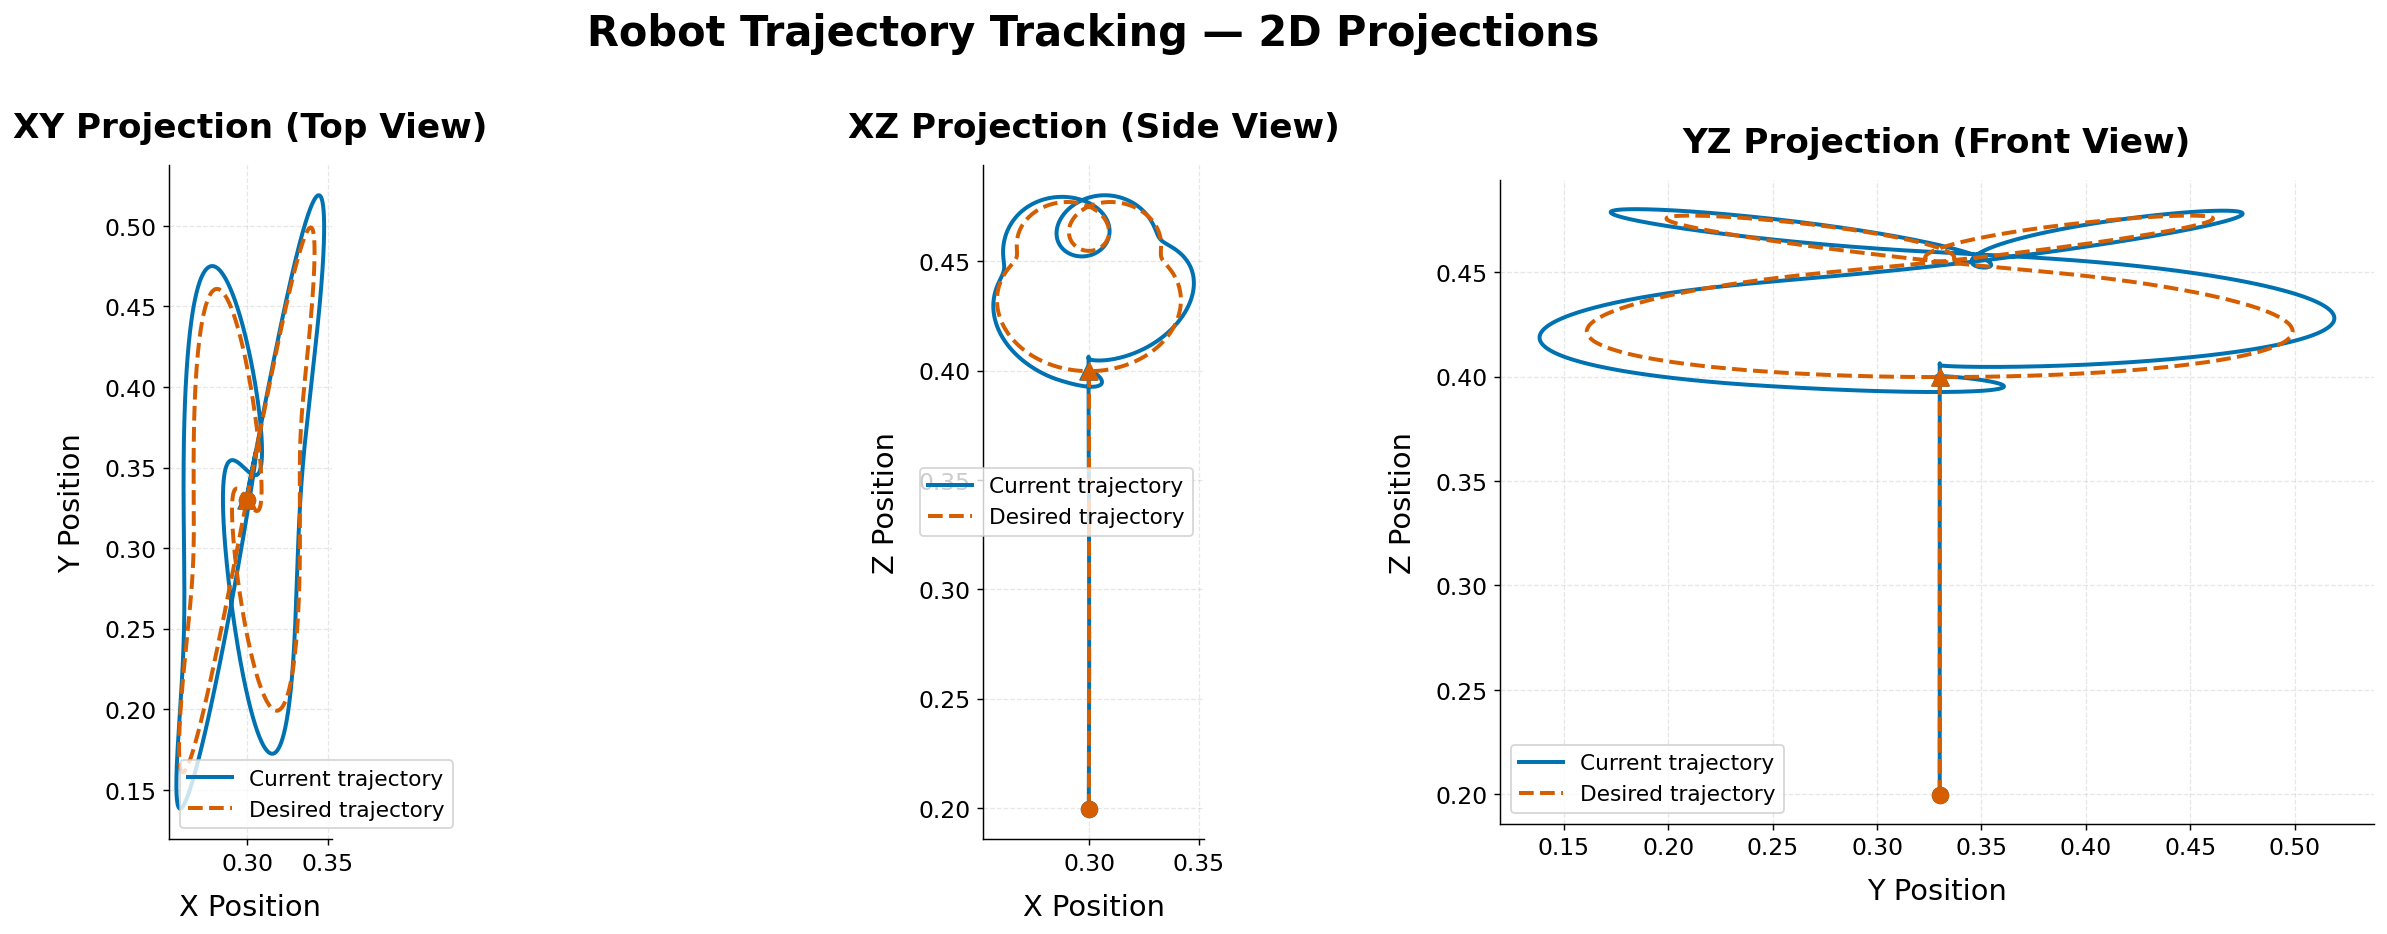

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Extract trajectory data
# ============================================================

current_columns = [
    "cooperative_Trajectory_Pose_Current_tx",
    "cooperative_Trajectory_Pose_Current_ty",
    "cooperative_Trajectory_Pose_Current_tz"
]

desired_columns = [
    "cooperative_Trajectory_Pose_Desired_tx",
    "cooperative_Trajectory_Pose_Desired_ty",
    "cooperative_Trajectory_Pose_Desired_tz"
]

# Convert trajectory values to numeric
trajectory_data = df[current_columns + desired_columns].apply(
    pd.to_numeric, errors="coerce"
)

# Replace infinite values and remove incomplete rows
trajectory_data = (
    trajectory_data
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# Extract coordinates
current = trajectory_data[current_columns].to_numpy()
desired = trajectory_data[desired_columns].to_numpy()

# Current trajectory
x_current, y_current, z_current = current.T

# Desired trajectory
x_desired, y_desired, z_desired = desired.T


# ============================================================
# 2. Plot appearance
# ============================================================

current_color = "#0072B2"
desired_color = "#D55E00"

line_width = 2.2

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 7),
    dpi=130
)


# ============================================================
# 3. Function to plot each 2D projection
# ============================================================

def plot_projection(ax, current_x, current_y,
                    desired_x, desired_y,
                    xlabel, ylabel, title):

    # Current trajectory
    ax.plot(
        current_x,
        current_y,
        color=current_color,
        linewidth=line_width,
        label="Current trajectory"
    )

    # Desired trajectory
    ax.plot(
        desired_x,
        desired_y,
        color=desired_color,
        linewidth=line_width,
        linestyle="--",
        label="Desired trajectory"
    )

    # Current trajectory: start and end
    ax.scatter(
        current_x[0], current_y[0],
        color=current_color,
        marker="o",
        s=75,
        zorder=3
    )

    ax.scatter(
        current_x[-1], current_y[-1],
        color=current_color,
        marker="^",
        s=85,
        zorder=3
    )

    # Desired trajectory: start and end
    ax.scatter(
        desired_x[0], desired_y[0],
        color=desired_color,
        marker="o",
        s=75,
        zorder=3
    )

    ax.scatter(
        desired_x[-1], desired_y[-1],
        color=desired_color,
        marker="^",
        s=85,
        zorder=3
    )

    # Titles and labels
    ax.set_title(
        title,
        fontsize=19,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(xlabel, fontsize=16, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=16, labelpad=10)

    ax.tick_params(axis="both", labelsize=13)

    # Grid
    ax.grid(
        True,
        linestyle="--",
        linewidth=0.7,
        alpha=0.3
    )

    # Preserve equal spatial scaling on both axes
    ax.set_aspect("equal", adjustable="box")

    # Clean up the plot borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        fontsize=12,
        loc="best",
        frameon=True
    )


# ============================================================
# 4. XY projection — Top view
# ============================================================

plot_projection(
    axes[0],
    x_current, y_current,
    x_desired, y_desired,
    "X Position", "Y Position",
    "XY Projection (Top View)"
)


# ============================================================
# 5. XZ projection — Side view
# ============================================================

plot_projection(
    axes[1],
    x_current, z_current,
    x_desired, z_desired,
    "X Position", "Z Position",
    "XZ Projection (Side View)"
)


# ============================================================
# 6. YZ projection — Front view
# ============================================================

plot_projection(
    axes[2],
    y_current, z_current,
    y_desired, z_desired,
    "Y Position", "Z Position",
    "YZ Projection (Front View)"
)


# ============================================================
# 7. Final layout
# ============================================================

fig.suptitle(
    "Robot Trajectory Tracking — 2D Projections",
    fontsize=23,
    fontweight="bold",
    y=1.02
)

fig.tight_layout()

# Save a high-resolution image if needed
# fig.savefig("robot_trajectory_2D.png",
#             dpi=300, bbox_inches="tight")

plt.show()

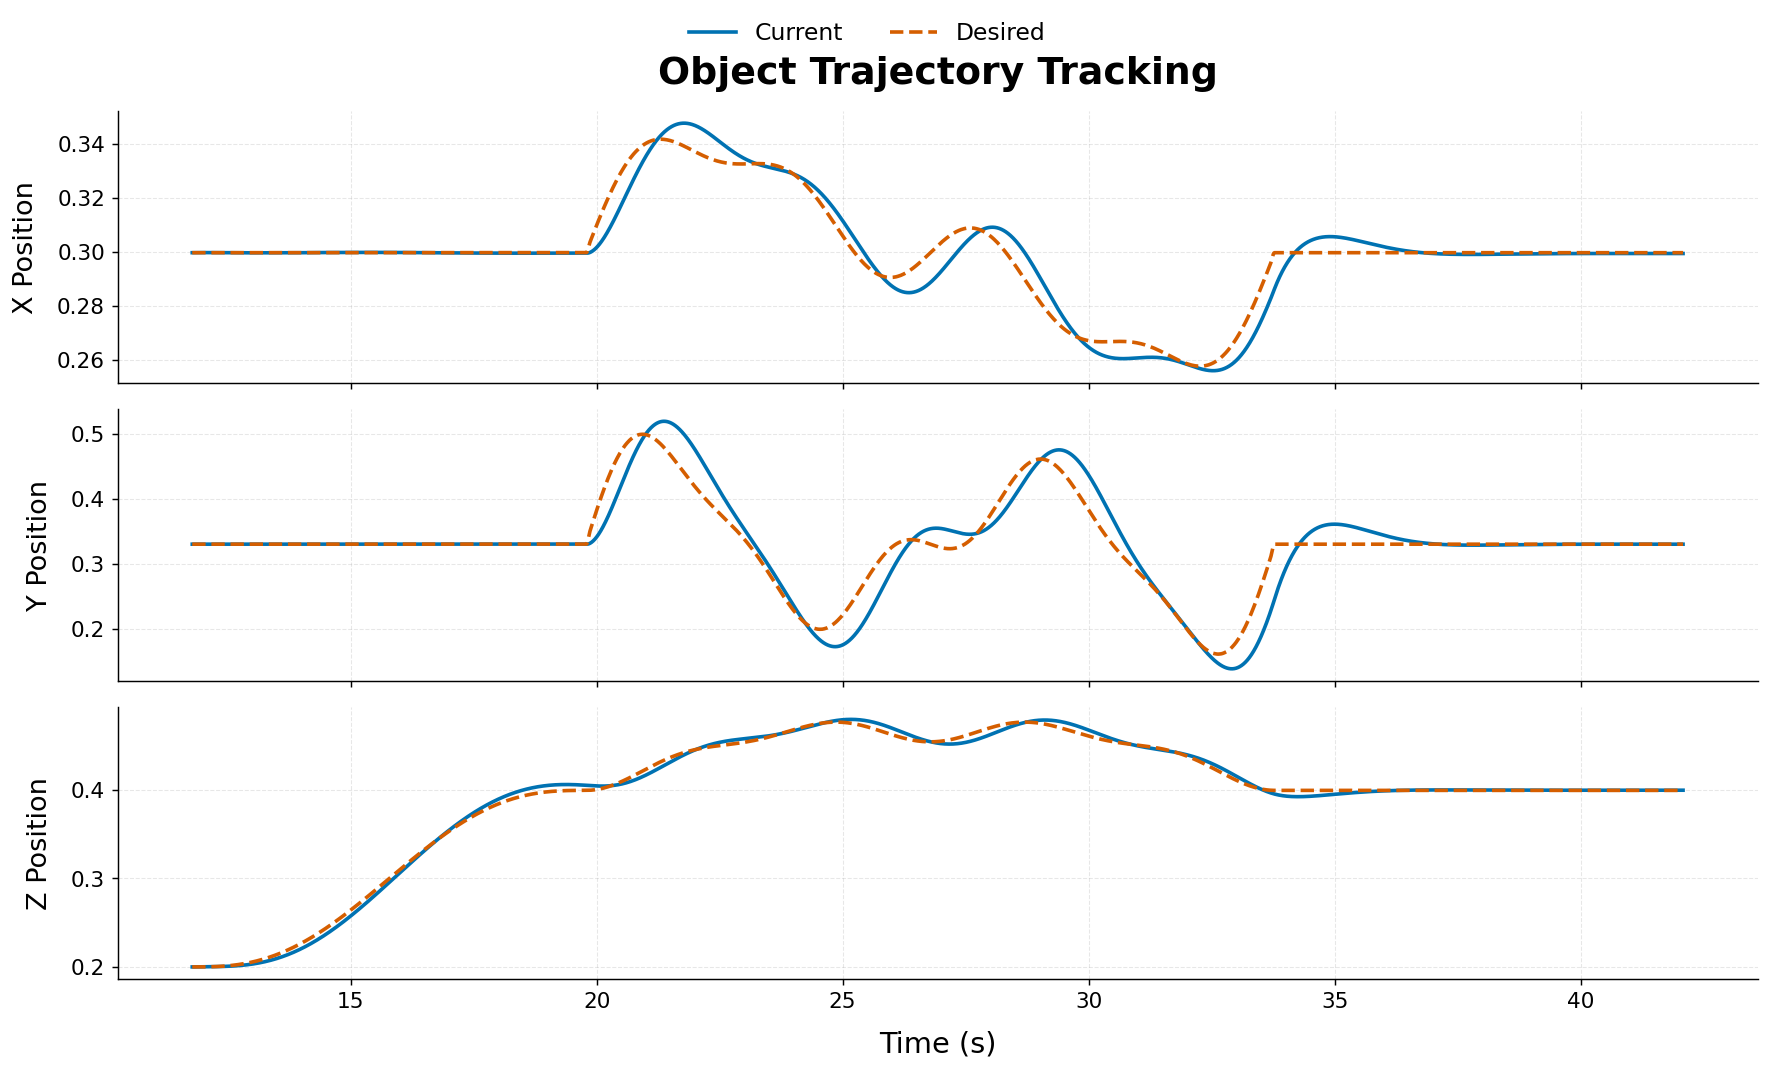

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Extract data
# ============================================================

current_columns = [
    "cooperative_Trajectory_Pose_Current_tx",
    "cooperative_Trajectory_Pose_Current_ty",
    "cooperative_Trajectory_Pose_Current_tz"
]

desired_columns = [
    "cooperative_Trajectory_Pose_Desired_tx",
    "cooperative_Trajectory_Pose_Desired_ty",
    "cooperative_Trajectory_Pose_Desired_tz"
]

# Keep time and all trajectory coordinates aligned
columns = ["t"] + current_columns + desired_columns

trajectory_data = df[columns].apply(
    pd.to_numeric, errors="coerce"
)

trajectory_data = (
    trajectory_data
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

time_plot = trajectory_data["t"].to_numpy()

current = trajectory_data[current_columns].to_numpy()
desired = trajectory_data[desired_columns].to_numpy()

# ============================================================
# 2. Create three vertically stacked subplots
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 9),
    dpi=130,
    sharex=True
)

# Colors and line styles
current_color = "#0072B2"
desired_color = "#D55E00"

coordinates = ["X", "Y", "Z"]

# ============================================================
# 3. Plot each coordinate
# ============================================================

for i, ax in enumerate(axes):

    # Current position
    ax.plot(
        time_plot,
        current[:, i],
        color=current_color,
        linewidth=2,
        label="Current"
    )

    # Desired position
    ax.plot(
        time_plot,
        desired[:, i],
        color=desired_color,
        linestyle="--",
        linewidth=2,
        label="Desired"
    )

    # Labels
    ax.set_ylabel(
        f"{coordinates[i]} Position",
        fontsize=15,
        labelpad=10
    )

    ax.tick_params(axis="both", labelsize=12)

    # Subtle grid
    ax.grid(
        True,
        linestyle="--",
        linewidth=0.6,
        alpha=0.3
    )

    # Clean appearance
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ============================================================
# 4. Titles and legend
# ============================================================

axes[0].set_title(
    "Object Trajectory Tracking",
    fontsize=21,
    fontweight="bold",
    pad=15
)

axes[-1].set_xlabel("Time (s)", fontsize=16, labelpad=10)

# One shared legend for the entire figure
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=2,
    fontsize=13,
    frameon=False
)

fig.tight_layout(rect=[0.02, 0.02, 1, 0.91])

# Optional: save in high resolution
fig.savefig("trajectory_xyz.png", dpi=300, bbox_inches="tight")

plt.show()

In [9]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Calculate tracking errors
# ============================================================

# Error = Desired position - Current position
# Column 0 = X, Column 1 = Y, Column 2 = Z

error = desired - current

error_x = error[:, 0]
error_y = error[:, 1]
error_z = error[:, 2]


# ============================================================
# 2. Calculate error metrics
# ============================================================

def calculate_metrics(error):
    return {
        "Mean Error [m]": np.mean(error),
        "MAE [m]": np.mean(np.abs(error)),
        "RMSE [m]": np.sqrt(np.mean(error**2)),
        "Standard Deviation [m]": np.std(error, ddof=1),
        "Maximum Absolute Error [m]": np.max(np.abs(error)),
        "Median Absolute Error [m]": np.median(np.abs(error))
    }


# ============================================================
# 3. Create the results table
# ============================================================

metrics_x = calculate_metrics(error_x)
metrics_y = calculate_metrics(error_y)
metrics_z = calculate_metrics(error_z)

trajectory_metrics = pd.DataFrame(
    {
        "X": metrics_x,
        "Y": metrics_y,
        "Z": metrics_z
    }
).T

trajectory_metrics.index.name = "Axis"

# Display results
display(trajectory_metrics.round(5))

,Mean Error [m],MAE [m],RMSE [m],Standard Deviation [m],Maximum Absolute Error [m],Median Absolute Error [m]
Axis,,,,,,
X,0.00041,0.00300,0.00471,0.00469,0.01400,0.00076
Y,-0.00003,0.01537,0.02530,0.02530,0.08759,0.00361
Z,-0.00002,0.00323,0.00416,0.00416,0.00842,0.00289


In [10]:
%load_ext manim

The manim module is not an IPython extension.


In [11]:
%%manim -qp Trajectory3D_2
# In Jupyter, put this as the first line of the cell:
# %%manim -ql Trajectory3D

from manim import *
import numpy as np
import pandas as pd
from pathlib import Path


# ========================================================
# Output size (the video is SQUARE)
# ========================================================
PREVIEW = False                      # False for the final render
SIDE = 540 if PREVIEW else 2160     # pixels per side


class Trajectory3D_2(ThreeDScene):

    # ---------------- data ----------------
    CSV_NAME = "3dharmonic.csv"
    MAX_POINTS = 600            # downsampling cap

    # ---------------- look ----------------
    BG_COLOR = "#101820"
    CURRENT_COLOR = TEAL_B
    DESIRED_COLOR = ORANGE
    ERROR_LOW = YELLOW          # small tracking error
    ERROR_HIGH = RED            # largest tracking error

    FIT = 4.4                   # largest side of the trajectory (frame is 8 x 8)
    TAIL = 0.14                 # comet tail length (fraction of the path)
    HAIR_COUNT = 60             # error "hairs" left behind along the path

    # ---------------- timing ----------------
    INTRO_TIME = 2.0
    TRACK_TIME = 12.0
    OUTRO_TIME = 3.0

    # ---------------- camera (eased over the whole shot) ----------------
    PHI_START, PHI_END = 70, 58          # elevation, degrees
    THETA_START, THETA_END = -65, 25     # azimuth, degrees
    ZOOM_START, ZOOM_END = 0.92, 1.08

    # --------------------------------------------------------
    # Force a square frame. This must happen BEFORE the scene
    # (and its camera) is created: setting it inside construct()
    # or at module level is too late / gets overridden by the
    # -ql preset, which is why the output was still 16:9.
    # --------------------------------------------------------
    def __init__(self, *args, **kwargs):
        config.pixel_width = SIDE
        config.pixel_height = SIDE
        config.frame_width = 8
        config.frame_height = 8
        super().__init__(*args, **kwargs)

    def construct(self):

        # ====================================================
        # 1. Load and clean the data
        # ====================================================
        csv_path = Path.cwd() / self.CSV_NAME

        df = pd.read_csv(csv_path, sep=";")
        df.columns = df.columns.str.strip()

        current_columns = [
            "cooperative_Trajectory_Pose_Current_tx",
            "cooperative_Trajectory_Pose_Current_ty",
            "cooperative_Trajectory_Pose_Current_tz",
        ]
        desired_columns = [
            "cooperative_Trajectory_Pose_Desired_tx",
            "cooperative_Trajectory_Pose_Desired_ty",
            "cooperative_Trajectory_Pose_Desired_tz",
        ]
        required_columns = current_columns + desired_columns

        missing = [c for c in required_columns if c not in df.columns]
        if missing:
            raise ValueError(f"Missing trajectory columns: {missing}")

        data = (
            df[required_columns]
            .apply(pd.to_numeric, errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )
        if len(data) < 2:
            raise ValueError("At least two valid trajectory samples are required.")

        if len(data) > self.MAX_POINTS:
            idx = np.linspace(0, len(data) - 1, self.MAX_POINTS).astype(int)
            data = data.iloc[idx]

        current = data[current_columns].to_numpy()
        desired = data[desired_columns].to_numpy()
        n = len(current)

        # ====================================================
        # 2. Data -> scene coordinates (uniform scale, centred)
        # ====================================================
        everything = np.vstack([current, desired])
        lo, hi = everything.min(axis=0), everything.max(axis=0)
        center = (lo + hi) / 2
        scale = self.FIT / max((hi - lo).max(), 1e-9)

        cur_pts = (current - center) * scale
        des_pts = (desired - center) * scale

        floor_z = min(cur_pts[:, 2].min(), des_pts[:, 2].min()) - 0.3
        radius = max(
            np.linalg.norm(cur_pts[:, :2], axis=1).max(),
            np.linalg.norm(des_pts[:, :2], axis=1).max(),
        ) + 0.4

        err = np.linalg.norm(current - desired, axis=1)
        err_norm = err / max(err.max(), 1e-12)

        def error_color(e):
            return interpolate_color(
                ManimColor(self.ERROR_LOW), ManimColor(self.ERROR_HIGH), float(e)
            )

        # ====================================================
        # 3. One timeline drives everything (motion + camera)
        # ====================================================
        total = self.TRACK_TIME + self.OUTRO_TIME
        timeline = ValueTracker(0.0)
        index_axis = np.arange(n)

        def idx():
            """Current (fractional) sample index."""
            return (n - 1) * float(
                np.clip(timeline.get_value() / self.TRACK_TIME, 0, 1)
            )

        def alpha():
            return float(np.clip(idx() / (n - 1), 1e-3, 1.0))

        def point_at(points, value):
            value = float(np.clip(value, 0, n - 1))
            i = int(value)
            j = min(i + 1, n - 1)
            a = value - i
            return (1 - a) * points[i] + a * points[j]

        def camera_pose(t):
            s = smooth(float(np.clip(t / total, 0, 1)))
            lerp = lambda a, b: a + (b - a) * s
            return (
                lerp(self.PHI_START, self.PHI_END) * DEGREES,
                lerp(self.THETA_START, self.THETA_END) * DEGREES,
                lerp(self.ZOOM_START, self.ZOOM_END),
            )

        # ====================================================
        # 4. Floor: polar grid (looks the same from every angle)
        # ====================================================
        floor = VGroup()
        for r in np.linspace(radius / 4, radius, 4):
            floor.add(Circle(radius=r).shift(OUT * floor_z))
        for ang in np.linspace(0, TAU, 12, endpoint=False):
            floor.add(
                Line(
                    [0, 0, floor_z],
                    [radius * np.cos(ang), radius * np.sin(ang), floor_z],
                )
            )
        floor.set_stroke(WHITE, width=1, opacity=0.12)

        # ====================================================
        # 5. Desired trajectory: thin dashed reference
        # ====================================================
        desired_src = VMobject().set_points_as_corners(des_pts)
        desired_path = DashedVMobject(
            desired_src, num_dashes=140, dashed_ratio=0.55
        ).set_stroke(self.DESIRED_COLOR, width=2, opacity=0.75)

        # ====================================================
        # 6. Current trajectory: history + fading comet tail
        # ====================================================
        cur_src = VMobject().set_points_as_corners(cur_pts)

        flat_pts = cur_pts.copy()
        flat_pts[:, 2] = floor_z
        shadow_src = VMobject().set_points_as_corners(flat_pts)

        def make_trail(source, tail, width, opacity, color):
            m = VMobject().set_stroke(color, width=width, opacity=opacity)
            m.add_updater(
                lambda mob: mob.pointwise_become_partial(
                    source, max(0.0, alpha() - tail), alpha()
                )
            )
            return m

        history = make_trail(cur_src, 1.0, 1.6, 0.30, self.CURRENT_COLOR)
        tail_outer = make_trail(cur_src, self.TAIL, 3.0, 0.50, self.CURRENT_COLOR)
        tail_mid = make_trail(cur_src, self.TAIL * 0.6, 4.5, 0.80, self.CURRENT_COLOR)
        tail_core = make_trail(cur_src, self.TAIL * 0.3, 6.0, 1.00, WHITE)
        floor_shadow = make_trail(shadow_src, 1.0, 2.0, 0.18, self.CURRENT_COLOR)

        # ====================================================
        # 7. Moving markers (with soft halo) + depth cues
        # ====================================================
        current_dot = Dot3D(radius=0.085, color=self.CURRENT_COLOR)
        desired_dot = Dot3D(radius=0.07, color=self.DESIRED_COLOR)
        current_halo = Dot3D(radius=0.17, color=self.CURRENT_COLOR).set_opacity(0.16)
        desired_halo = Dot3D(radius=0.14, color=self.DESIRED_COLOR).set_opacity(0.16)

        current_dot.add_updater(lambda m: m.move_to(point_at(cur_pts, idx())))
        current_halo.add_updater(lambda m: m.move_to(point_at(cur_pts, idx())))
        desired_dot.add_updater(lambda m: m.move_to(point_at(des_pts, idx())))
        desired_halo.add_updater(lambda m: m.move_to(point_at(des_pts, idx())))

        # Vertical drop line + dot on the floor under the current position
        drop_line = VMobject().set_stroke(self.CURRENT_COLOR, width=1.2, opacity=0.35)

        def update_drop(m):
            p = point_at(cur_pts, idx())
            m.set_points_as_corners([p, [p[0], p[1], floor_z]])

        drop_line.add_updater(update_drop)

        floor_dot = Dot(radius=0.05, color=self.CURRENT_COLOR).set_opacity(0.4)
        floor_dot.add_updater(
            lambda m: m.move_to(
                [*point_at(cur_pts, idx())[:2], floor_z]
            )
        )

        start_marker = Dot3D(
            point=cur_pts[0], radius=0.05, color=WHITE
        ).set_opacity(0.8)

        # ====================================================
        # 8. Instantaneous error line + error "hairs" left behind
        # ====================================================
        error_line = VMobject()

        def update_error(m):
            v = idx()
            e = np.interp(v, index_axis, err_norm)
            m.set_points_as_corners([point_at(cur_pts, v), point_at(des_pts, v)])
            m.set_stroke(error_color(e), width=3.5, opacity=1)

        error_line.add_updater(update_error)

        hair_ids = list(
            np.unique(np.linspace(0, n - 1, self.HAIR_COUNT).astype(int))
        )
        hairs = VGroup()
        for i in hair_ids:
            h = VMobject().set_points_as_corners([cur_pts[i], des_pts[i]])
            h.set_stroke(error_color(err_norm[i]), width=1.5, opacity=0)
            hairs.add(h)

        def update_hairs(group):
            v = idx()
            for i, h in zip(hair_ids, group):
                h.set_stroke(opacity=0.32 if i <= v else 0)

        hairs.add_updater(update_hairs)

        # ====================================================
        # 9. Camera: driven by the same timeline, smooth ease
        # ====================================================
        self.camera.background_color = self.BG_COLOR

        phi0, theta0, zoom0 = camera_pose(0)
        self.set_camera_orientation(phi=phi0, theta=theta0, zoom=zoom0)

        camera_driver = Mobject()

        def drive_camera(_m):
            phi, theta, zoom = camera_pose(timeline.get_value())
            self.set_camera_orientation(phi=phi, theta=theta, zoom=zoom)

        camera_driver.add_updater(drive_camera)

        # ====================================================
        # 10. Intro: floor + reference path appear
        # ====================================================
        # IMPORTANT: add the camera driver BEFORE any other mobject.
        # Manim caches mobjects that come before the first "moving" one as a
        # static image. A camera moved by an updater is not detected as moving,
        # so anything added earlier (floor, reference path) would stay frozen in
        # the first camera view while the rest orbits. Putting the driver first
        # keeps everything live.
        self.add(camera_driver)
        self.play(
            FadeIn(floor),
            Create(desired_path),
            FadeIn(start_marker),
            run_time=self.INTRO_TIME,
        )

        # ====================================================
        # 11. Tracking + outro in one continuous shot
        # ====================================================
        self.add(
            floor_shadow,
            hairs,
            history,
            tail_outer,
            tail_mid,
            tail_core,
            drop_line,
            floor_dot,
            error_line,
            desired_halo,
            current_halo,
            desired_dot,
            current_dot,
        )

        self.play(
            timeline.animate.set_value(total),
            run_time=total,
            rate_func=linear,
        )

        self.wait(0.5)

Manim Community v0.19.1

[10/22/26 17:29:58] INFO     Animation 0 : Partial movie file written in                   ]8;id=12302068;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py\scene_file_writer.py]8;;\:]8;id=12302069;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py#590\590]8;;\
                             '/home/luca/superbuild/workspace/sandbox/controllers/FSM-Dual                         
                             Manipulation/Logs/media/videos/Logs/2160p60/partial_movie_fil                         
                             es/Trajectory3D_2/3053816884_347471600_1042866279.mp4'                                

[10/22/26 17:31:09] INFO     Animation 1 : Partial movie file written in                   ]8;id=12302074;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py\scene_file_writer.py]8;;\:]8;id=12302075;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py#590\590]8;;\
                             '/home/luca/superbuild/workspace/sandbox/controllers/FSM-Dual                         
                             Manipulation/Logs/media/videos/Logs/2160p60/partial_movie_fil                         
                             es/Trajectory3D_2/2004037282_1361106616_3016234922.mp4'                               

[10/22/26 17:31:10] INFO     Animation 2 : Partial movie file written in                   ]8;id=12302080;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py\scene_file_writer.py]8;;\:]8;id=12302081;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py#590\590]8;;\
                             '/home/luca/superbuild/workspace/sandbox/controllers/FSM-Dual                         
                             Manipulation/Logs/media/videos/Logs/2160p60/partial_movie_fil                         
                             es/Trajectory3D_2/214941105_2840115676_63851050.mp4'                                  

                    INFO     Combining to Movie file.                                      ]8;id=12302087;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py\scene_file_writer.py]8;;\:]8;id=12302088;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py#740\740]8;;\

                    INFO                                                                   ]8;id=12302094;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py\scene_file_writer.py]8;;\:]8;id=12302095;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene_file_writer.py#887\887]8;;\
                             File ready at                                                                         
                             '/home/luca/superbuild/workspace/sandbox/controllers/FSM-Dual                         
                             Manipulation/Logs/media/videos/Logs/2160p60/Trajectory3D_2.mp                         
                             4'                                                                                    
                                                                                                                   

                    INFO     Rendered Trajectory3D_2                                                   ]8;id=12302102;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene.py\scene.py]8;;\:]8;id=12302103;file:///home/luca/.local/lib/python3.10/site-packages/manim/scene/scene.py#279\279]8;;\
                             Played 3 animations                                                                   